# Modeling of employee attrition

TechNova Partners faces unusually high attrition, and the HR team wants to understand the potential causes of resignations. In this notebook we prepare the cleaned table, train a classifier that scores each employee's probability of leaving, and explain its behavior with SHAP.

## 0. Setup

The cleaned table comes from the exploration notebook, so run it first.

In [1]:
import json
import math
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "grid.color": "#e5e5e5",
        "grid.linewidth": 0.8,
        "legend.frameon": False,
        "axes.titlesize": 13,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
        "figure.figsize": (8, 4.5),
    }
)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

RANDOM_STATE = 42
PROCESSED_DIR = Path("../data/processed")

employees = pd.read_parquet(PROCESSED_DIR / "employees_cleaned.parquet")
with open(PROCESSED_DIR / "metadata.json", encoding="utf-8") as f:
    metadata = json.load(f)

EMPLOYEE_KINDS = metadata["employee_kinds"]
CATEGORY_ORDERS = metadata["category_orders"]
TARGET = metadata["target"]

# Target values stay "Oui" and "Non" in the data, with English labels for charts only
TARGET_LABELS = {"Oui": "Left", "Non": "Stayed"}
TARGET_COLORS = {"Left": "#d95f02", "Stayed": "#9e9e9e"}

# Neutral color of the bars that show a leaving rate
RATE_BAR_COLOR = "#4c78a8"

# Readable English labels for charts and tables, with the encoded columns spelled out
COLUMN_LABELS = {
    **metadata["column_labels"],
    "genre": "Gender (male = 1)",
    "heures_supplementaires": "Works overtime (yes = 1)",
    "frequence_deplacement": "Business travel frequency (0 to 2)",
    TARGET: "Left the company (yes = 1)",
    "satisfaction_lows": "Satisfaction scores at 1 (count, 0 to 3 or more)",
    "career_share_in_company": "Career share in the company (0 to 1)",
    "role_share_of_tenure": "Role share of the tenure (0 to 1)",
    "promotion_wait_share": "Promotion wait share of the tenure (0 to 1)",
    "years_per_employer": "Experience per employer (years)",
}

print(f"Loaded {employees.shape[0]} rows x {employees.shape[1]} columns")

Loaded 1470 rows x 28 columns


In [2]:
def make_grid(n_panels, panel_height, sharex=False, n_cols=3, width=13):
    """Create a grid of n_cols columns with one panel per item, and hide the unused panels."""
    n_rows = math.ceil(n_panels / n_cols)
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(width, panel_height * n_rows),
        sharex=sharex,
        squeeze=False,
        layout="constrained",
    )
    fig.get_layout_engine().set(w_pad=0.25, h_pad=0.25, wspace=0.12, hspace=0.12)
    for ax in axes.flat[n_panels:]:
        ax.set_visible(False)
    return fig, axes.flat[:n_panels]


def plot_boxplots_by_target(df, columns, title):
    """Draw one boxplot panel per column, comparing stayers and leavers."""
    labels = ["Stayed", "Left"]
    status = df[TARGET].map(TARGET_LABELS)
    sizes = {label: int((status == label).sum()) for label in labels}
    fig, axes = make_grid(len(columns), panel_height=3.4)
    for ax, col in zip(axes, columns):
        boxes = ax.boxplot(
            [df.loc[status == label, col] for label in labels],
            patch_artist=True,
            medianprops={"color": "black"},
        )
        for box, label in zip(boxes["boxes"], labels):
            box.set_facecolor(TARGET_COLORS[label])
        ax.set_xticks(
            [1, 2], labels=[f"{label} (n={size:,})" for label, size in sizes.items()]
        )
        ax.set_title(COLUMN_LABELS[col], fontsize=10)
    fig.suptitle(title, fontsize=14, fontweight="bold")
    plt.show()


def plot_leaving_rate_by_value(df, columns, title, n_cols=3, width=13):
    """Draw one panel per column with the leaving rate of each value and its group size."""
    is_leaver = df[TARGET].eq("Oui")
    overall_rate = is_leaver.mean() * 100
    rates = {}
    for col in columns:
        stats = is_leaver.groupby(df[col]).agg(rate="mean", size="size")
        stats["rate"] *= 100
        if col in CATEGORY_ORDERS:
            stats = stats.loc[CATEGORY_ORDERS[col]]
        elif pd.api.types.is_numeric_dtype(df[col]):
            stats = stats.sort_index()
        else:
            stats = stats.sort_values("rate", ascending=False)
        rates[col] = stats

    longest = max(len(stats) for stats in rates.values())
    fig, axes = make_grid(
        len(columns),
        panel_height=0.3 * longest + 1.6,
        sharex=True,
        n_cols=n_cols,
        width=width,
    )
    x_max = max(stats["rate"].max() for stats in rates.values()) * 1.3
    for ax, (col, stats) in zip(axes, rates.items()):
        bars = ax.barh(stats.index.astype(str), stats["rate"], color=RATE_BAR_COLOR)
        ax.bar_label(bars, labels=[f"n={size:,}" for size in stats["size"]], padding=3)
        line = ax.axvline(
            overall_rate,
            color=TARGET_COLORS["Left"],
            linestyle="--",
            linewidth=1,
            label=f"Overall rate ({overall_rate:.0f}%)",
        )
        ax.invert_yaxis()
        ax.set_xlim(0, x_max)
        ax.set_title(COLUMN_LABELS[col], fontsize=10)
        ax.set_xlabel("Leaving rate (%)")
        ax.tick_params(labelbottom=True)
        ax.grid(axis="x")
        ax.grid(axis="y", visible=False)
    # Leave a band at the top for the title and the legend, which sits under the title
    height = fig.get_figheight()
    fig.get_layout_engine().set(rect=(0, 0, 1, 1 - 0.7 / height))
    fig.suptitle(title, y=1, fontsize=14, fontweight="bold")
    fig.legend(
        handles=[line], loc="upper center", bbox_to_anchor=(0.5, 1 - 0.4 / height)
    )
    plt.show()

## 1. Correlations between the raw variables

We look for redundancies before any feature engineering, on the numeric variables with business travel and the two binaries encoded as numbers.

In [3]:
numeric_columns = [
    col
    for col, kind in EMPLOYEE_KINDS.items()
    if kind in ("ordinal", "quantitative") and col != "frequence_deplacement"
]
assert len(numeric_columns) == 20

travel_order = {
    value: rank for rank, value in enumerate(CATEGORY_ORDERS["frequence_deplacement"])
}

encoded = employees[numeric_columns].copy()
encoded["frequence_deplacement"] = employees["frequence_deplacement"].map(travel_order)
encoded["genre"] = (employees["genre"] == "M").astype(int)
encoded["heures_supplementaires"] = (
    employees["heures_supplementaires"] == "Oui"
).astype(int)

# Variables of the same theme sit side by side, and the target comes last
SENIORITY_BLOCK = [
    "niveau_hierarchique_poste",
    "revenu_mensuel",
    "annees_experience_totale",
    "age",
]
TENURE_BLOCK = [
    "annees_dans_l_entreprise",
    "annees_dans_le_poste_actuel",
    "annees_sous_responsable_actuel",
    "annees_depuis_la_derniere_promotion",
]
grouped = SENIORITY_BLOCK + TENURE_BLOCK
other_columns = [col for col in encoded.columns if col not in grouped]

encoded[TARGET] = (employees[TARGET] == "Oui").astype(int)
encoded = encoded[grouped + other_columns + [TARGET]]

assert encoded.notna().all().all()
print(f"{encoded.shape[1]} columns: {encoded.shape[1] - 1} variables and the target")

24 columns: 23 variables and the target


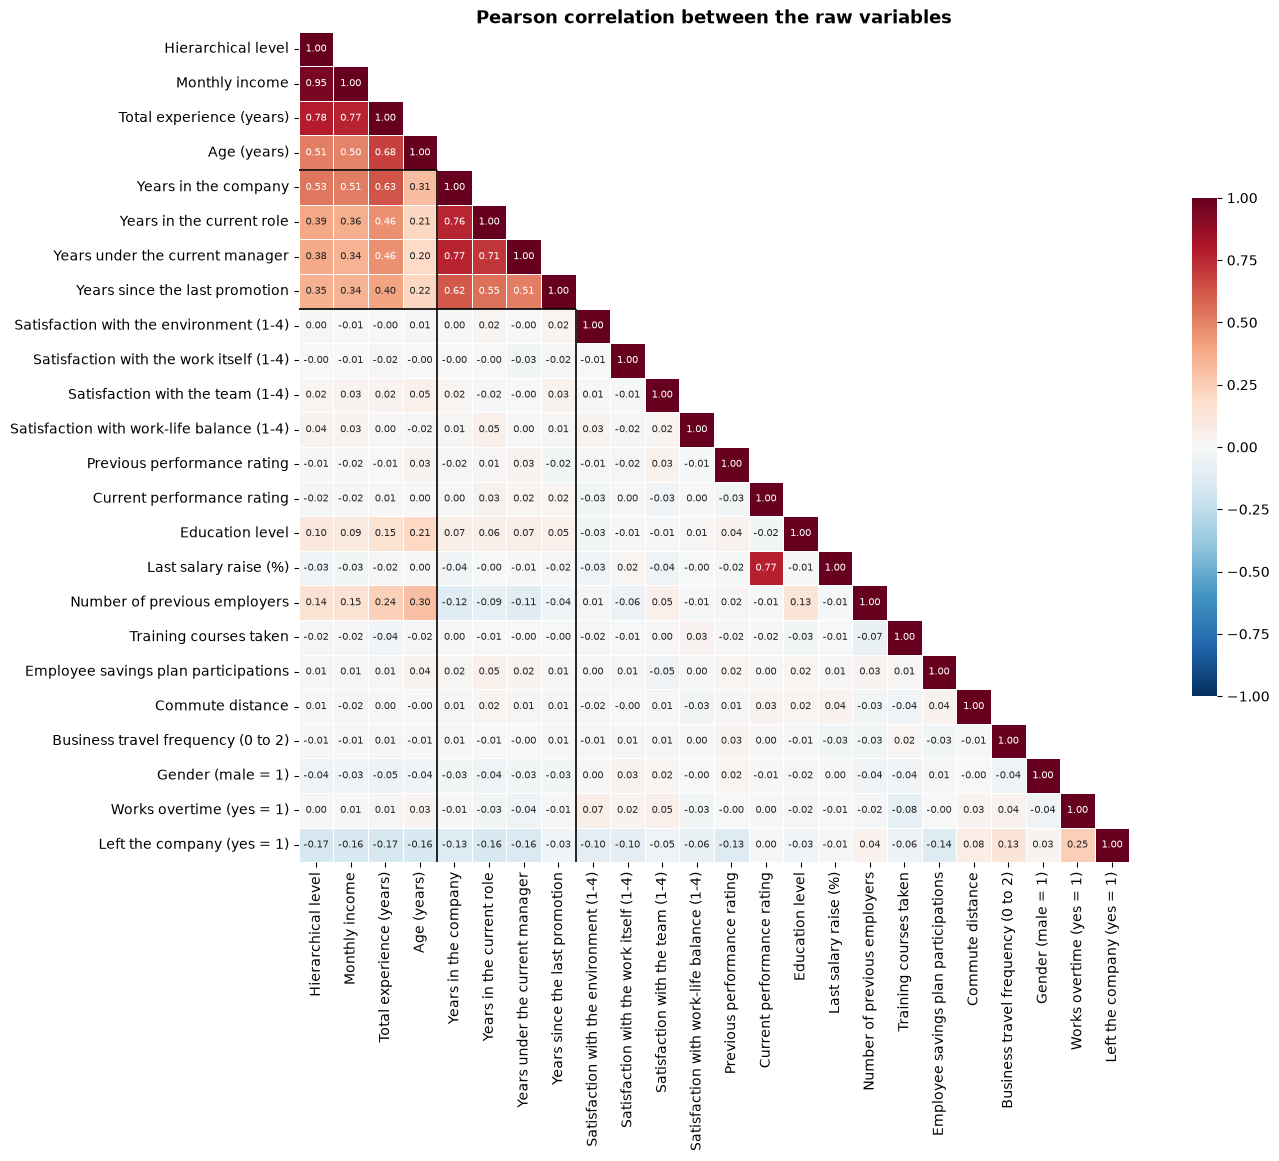

In [4]:
pearson = encoded.corr(method="pearson")
labels = [COLUMN_LABELS[col] for col in pearson.columns]

fig, ax = plt.subplots(figsize=(14, 11.5), layout="constrained")
sns.heatmap(
    pearson,
    mask=np.triu(np.ones_like(pearson, dtype=bool), k=1),
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": 7},
    linewidths=0.5,
    linecolor="white",
    square=True,
    xticklabels=labels,
    yticklabels=labels,
    cbar_kws={"shrink": 0.6},
    ax=ax,
)
for edge in (len(SENIORITY_BLOCK), len(grouped)):
    ax.hlines(edge, 0, edge, color="black", linewidth=1.2)
    ax.vlines(edge, edge, len(pearson), color="black", linewidth=1.2)
ax.grid(False)
ax.set_title("Pearson correlation between the raw variables")
plt.show()

In [5]:
REDUNDANCY_THRESHOLD = 0.7

spearman = encoded.corr(method="spearman")

first, second = np.triu_indices(len(pearson), k=1)
pairs = pd.DataFrame(
    {
        "Variable A": [COLUMN_LABELS[pearson.columns[i]] for i in first],
        "Variable B": [COLUMN_LABELS[pearson.columns[j]] for j in second],
        "Pearson": pearson.values[first, second],
        "Spearman": spearman.values[first, second],
    }
)
strong_pairs = (
    pairs[pairs["Pearson"].abs() >= REDUNDANCY_THRESHOLD]
    .sort_values("Pearson", key=abs, ascending=False)
    .reset_index(drop=True)
    .round(2)
)
display(strong_pairs)

satisfaction_columns = [
    col for col in numeric_columns if col.startswith("satisfaction_")
]
satisfaction_corr = pearson.loc[satisfaction_columns, satisfaction_columns].to_numpy()
print(
    "Largest correlation between two satisfaction scores:",
    round(float(np.abs(satisfaction_corr[np.triu_indices(4, k=1)]).max()), 2),
)

,Variable A,Variable B,Pearson,Spearman
0,Hierarchical level,Monthly income,0.95,0.92
1,Hierarchical level,Total experience (years),0.78,0.73
2,Current performance rating,Last salary raise (%),0.77,0.63
3,Monthly income,Total experience (years),0.77,0.71
4,Years in the company,Years under the current manager,0.77,0.84
5,Years in the company,Years in the current role,0.76,0.85
6,Years in the current role,Years under the current manager,0.71,0.72


Largest correlation between two satisfaction scores: 0.03


Two blocks stand out, seniority and time in the company, and the rating and the raise link unexpectedly at 0.77.

The target row shows weak links for satisfaction (-0.05 to -0.10) and business travel (0.13) despite the large gaps in leaving rate seen in the exploration, because Pearson only sees straight lines.

## 2. Feature engineering

We add five features that restate existing columns as counts and ratios, each computed from a single employee's row so that nothing leaks before the split.

- `satisfaction_lows` counts the satisfaction scores at 1, capped at 3 to mean 3 or more.
- `career_share_in_company` is the share of the total experience spent in the company, and takes 1 when the experience is 0.
- `role_share_of_tenure` is the share of the years in the company spent in the current role, and takes 1 when the tenure is 0.
- `promotion_wait_share` is the share of the years in the company spent since the last promotion, and takes 0 when the tenure is 0.
- `years_per_employer` is the total experience divided by the number of employers, the current one included.

In [6]:
SATISFACTION_COLUMNS = [
    col for col in employees.columns if col.startswith("satisfaction_employee_")
]
FEATURE_COLUMNS = [
    "satisfaction_lows",
    "career_share_in_company",
    "role_share_of_tenure",
    "promotion_wait_share",
    "years_per_employer",
]


def add_engineered_features(df):
    """Return the five engineered features of df, row by row.

    A ratio whose denominator is 0 takes a neutral value: 1 for the two shares of
    time already spent (a new hire has spent all of its tenure in the company and
    in the role), and 0 for the promotion wait.
    """
    experience = df["annees_experience_totale"]
    tenure = df["annees_dans_l_entreprise"]
    features = pd.DataFrame(index=df.index)
    features["satisfaction_lows"] = (
        (df[SATISFACTION_COLUMNS] == 1).sum(axis=1).clip(upper=3)
    )
    features["career_share_in_company"] = (tenure / experience).where(
        experience > 0, 1.0
    )
    features["role_share_of_tenure"] = (
        df["annees_dans_le_poste_actuel"] / tenure
    ).where(tenure > 0, 1.0)
    features["promotion_wait_share"] = (
        df["annees_depuis_la_derniere_promotion"] / tenure
    ).where(tenure > 0, 0.0)
    features["years_per_employer"] = experience / (
        df["nombre_experiences_precedentes"] + 1
    )
    return features[FEATURE_COLUMNS]


features = add_engineered_features(employees)
assert features.notna().all().all(), "a feature has a missing value"
assert np.isfinite(features).all().all(), "a feature has an infinite value"
assert set(FEATURE_COLUMNS) <= set(COLUMN_LABELS), "a feature has no label"

engineered = employees.join(features)
display(features.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
satisfaction_lows,1470.0,0.63,0.73,0.0,0.00,1.00,1.00,3.0
career_share_in_company,1470.0,0.69,0.32,0.0,0.43,0.80,1.00,1.0
role_share_of_tenure,1470.0,0.61,0.32,0.0,0.40,0.67,0.88,1.0
promotion_wait_share,1470.0,0.29,0.34,0.0,0.00,0.17,0.50,1.0
years_per_employer,1470.0,4.19,4.04,0.0,1.60,3.00,5.00,38.0


### Ratios

We compare the four ratios between leavers and stayers, to see whether they separate the two groups better than the raw durations.

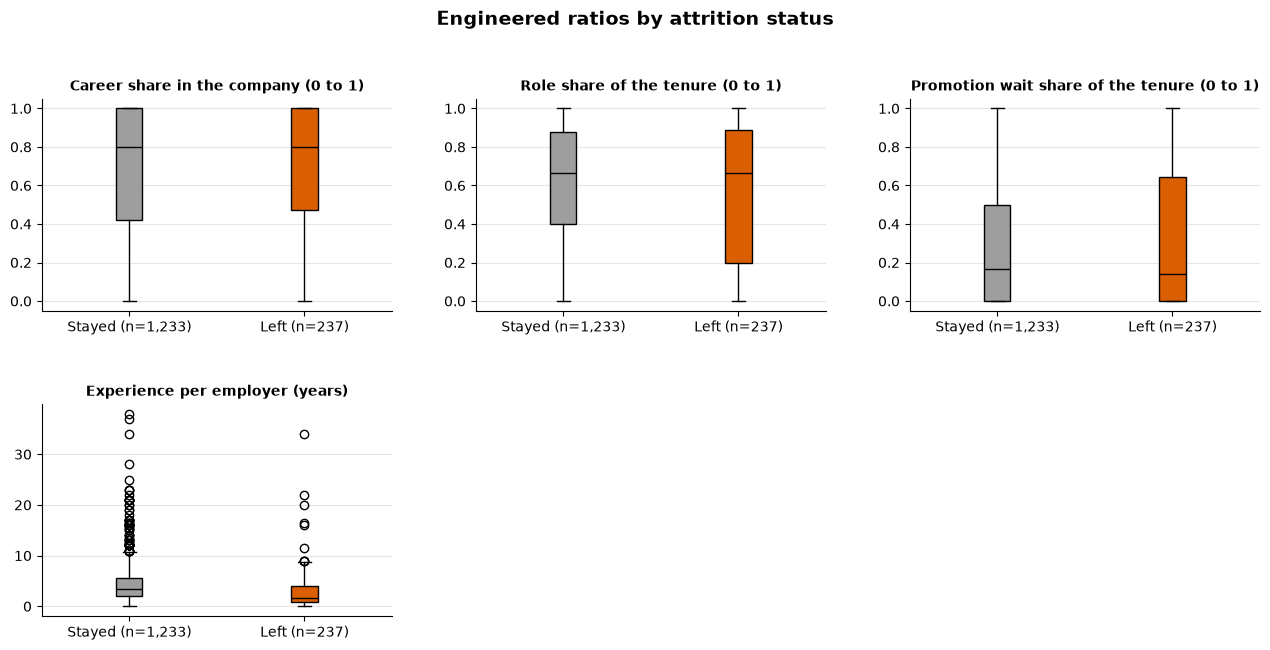

In [7]:
RATIO_COLUMNS = FEATURE_COLUMNS[1:]
plot_boxplots_by_target(
    engineered, RATIO_COLUMNS, "Engineered ratios by attrition status"
)

Leavers have a median of 1.6 years of experience per employer against 3.3 for stayers, while the three shares of tenure show almost no gap.

### Satisfaction scores at 1

We look at the leaving rate for each count of scores at 1, with the group sizes to avoid reading too much into small groups.

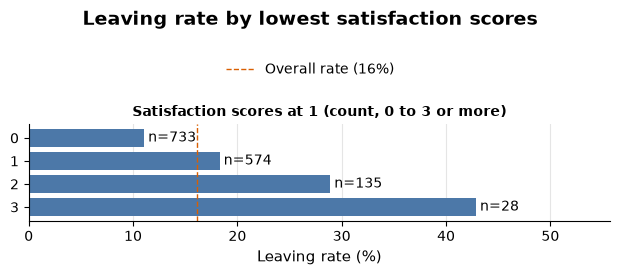

In [8]:
plot_leaving_rate_by_value(
    engineered,
    ["satisfaction_lows"],
    "Leaving rate by lowest satisfaction scores",
    n_cols=1,
    width=6.5,
)

The leaving rate climbs with each score at 1, from 11% with none to 29% with two and 43% with three or more.

## 3. Final redundancy check and decisions

We check the redundancies again with the five engineered features by listing every pair that reaches 0.7 in Pearson or in Spearman.

In [9]:
DROPS = {}


def correlated_pairs(df, threshold):
    """List the pairs of columns whose Pearson or Spearman correlation reaches the threshold."""
    pearson = df.corr(method="pearson")
    spearman = df.corr(method="spearman")
    first, second = np.triu_indices(len(pearson), k=1)
    pairs = pd.DataFrame(
        {
            "Variable A": [COLUMN_LABELS[pearson.columns[i]] for i in first],
            "Variable B": [COLUMN_LABELS[pearson.columns[j]] for j in second],
            "Pearson": pearson.values[first, second],
            "Spearman": spearman.values[first, second],
        }
    )
    keep = (pairs[["Pearson", "Spearman"]].abs() >= threshold).any(axis=1)
    return (
        pairs[keep]
        .sort_values("Pearson", key=abs, ascending=False)
        .reset_index(drop=True)
        .round(2)
    )


with_features = encoded.drop(columns=TARGET).join(features)
assert with_features.shape[1] == 28
display(correlated_pairs(with_features, REDUNDANCY_THRESHOLD))

,Variable A,Variable B,Pearson,Spearman
0,Hierarchical level,Monthly income,0.95,0.92
1,Hierarchical level,Total experience (years),0.78,0.73
2,Current performance rating,Last salary raise (%),0.77,0.63
3,Monthly income,Total experience (years),0.77,0.71
4,Years in the company,Years under the current manager,0.77,0.84
5,Years in the company,Years in the current role,0.76,0.85
6,Years in the current role,Years under the current manager,0.71,0.72
7,Years in the company,Experience per employer (years),0.70,0.67
8,Years since the last promotion,Promotion wait share of the tenure (0 to 1),0.63,0.91


Seven pairs repeat the first matrix and two are new, the years in the company with the years per employer (0.70) and the years since the last promotion with the promotion wait share (0.91 in Spearman).

We plot the seniority and time variables against each other, colored by status, to see whether the links hold over the whole range.

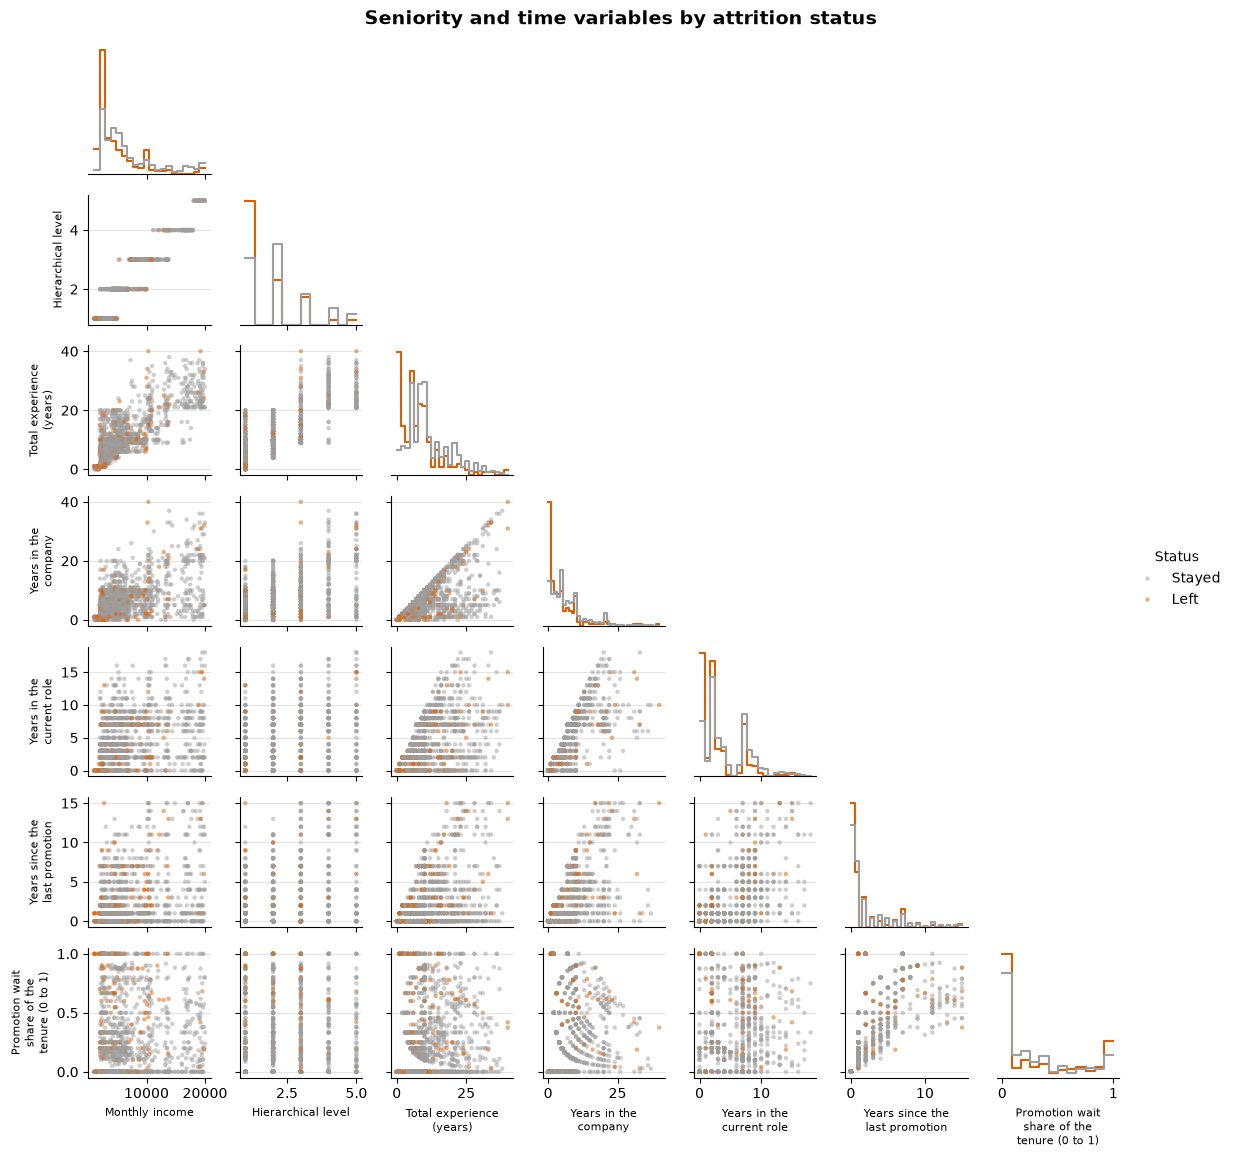

In [10]:
PAIRPLOT_COLUMNS = [
    "revenu_mensuel",
    "niveau_hierarchique_poste",
    "annees_experience_totale",
    "annees_dans_l_entreprise",
    "annees_dans_le_poste_actuel",
    "annees_depuis_la_derniere_promotion",
    "promotion_wait_share",
]

pairplot_data = engineered[PAIRPLOT_COLUMNS].assign(
    Status=employees[TARGET].map(TARGET_LABELS)
)
grid = sns.PairGrid(
    pairplot_data,
    hue="Status",
    hue_order=["Stayed", "Left"],
    palette=TARGET_COLORS,
    corner=True,
    diag_sharey=False,
    height=1.6,
)
grid.map_lower(sns.scatterplot, s=10, alpha=0.5, edgecolor="none")
grid.map_diag(
    sns.histplot, element="step", fill=False, stat="density", common_norm=False
)
grid.add_legend(title="Status")
for ax in grid.axes.flat:
    if ax is not None:
        ax.set_xlabel(
            textwrap.fill(COLUMN_LABELS.get(ax.get_xlabel(), ""), 18), fontsize=8
        )
        ax.set_ylabel(
            textwrap.fill(COLUMN_LABELS.get(ax.get_ylabel(), ""), 18), fontsize=8
        )
grid.figure.suptitle(
    "Seniority and time variables by attrition status",
    y=1.01,
    fontsize=14,
    fontweight="bold",
)
plt.show()

Monthly income rises in steps with the hierarchical level, and the promotion wait share follows the years since the last promotion along a fan of lines, one per tenure, which Spearman captures better than Pearson.

### Seniority

The hierarchical level reaches 0.95 with the monthly income, while income and total experience (0.77) measure pay and career length.

#### Decision

We remove the hierarchical level, since income is finer and a lever HR can act on, and keep the income and the experience.

In [11]:
DROPS["niveau_hierarchique_poste"] = "Same seniority as income (0.95)"

### Time in the company

The years in the current role can be rebuilt from the role share, and the years since the last promotion reach 0.91 in Spearman with the promotion wait share.

#### Decision

We remove the years in the current role and the years since the last promotion, and keep the years under the current manager and the years per employer, which add the stability of management and the pace of changing employers.

In [12]:
DROPS["annees_dans_le_poste_actuel"] = (
    "Rebuilt from the role share and the years in the company"
)
DROPS["annees_depuis_la_derniere_promotion"] = (
    "Kept as the promotion wait share (0.91 in Spearman)"
)

### Rating and raise

The current performance rating reaches 0.77 with the last salary raise, and it takes only two values.

#### Decision

We remove the current rating and keep the raise, which carries more detail.

In [13]:
DROPS["note_evaluation_actuelle"] = "Two values only, redundant with the raise (0.77)"

### Department and job title

The department could be a copy of the job title, so we count the employees and the leaving rate for each pair of job title and department.

In [14]:
role_department = (
    employees.groupby(["poste", "departement"])[TARGET]
    .agg(Employees="size", Leavers=lambda s: (s == "Oui").sum())
    .assign(
        **{"Leaving rate (%)": lambda t: (t["Leavers"] / t["Employees"] * 100).round()}
    )
    .astype(int)
    .rename_axis(index=["Job title", "Department"])
)
display(role_department)

departments_per_role = employees.groupby("poste")["departement"].nunique()
assert list(departments_per_role[departments_per_role > 1].index) == ["Senior Manager"]

Employees  Leavers  \
Job title               Department                                
Assistant de Direction  Consulting                 292       47   
Cadre Commercial        Commercial                 326       57   
Consultant              Consulting                 259       62   
Directeur Technique     Consulting                  80        2   
Manager                 Consulting                 131        9   
Représentant Commercial Commercial                  83       33   
Ressources Humaines     Ressources Humaines         52       12   
Senior Manager          Commercial                  37        2   
                        Consulting                  54        3   
                        Ressources Humaines         11        0   
Tech Lead               Consulting                 145       10   

                                             Leaving rate (%)  
Job title               Department                             
Assistant de Direction  Consulting                         16  
Cadre Commercial        Commercial                         17  
Consultant              Consulting                         24  
Directeur Technique     Consulting                          2  
Manager                 Consulting                          7  
Représentant Commercial Commercial                         40  
Ressources Humaines     Ressources Humaines                23  
Senior Manager          Commercial                          5  
                        Consulting                          6  
                        Ressources Humaines                 0  
Tech Lead               Consulting                          7

Each job title sits in a single department except Senior Manager, which spans three with leaving rates of 0 to 6%.

#### Decision

We remove the department, since it follows from the job title.

In [15]:
DROPS["departement"] = "Follows from the job title"

## 4. Inputs X and y

The registry holds the variables removed above and the reason for each.

In [16]:
display(
    pd.Series(DROPS, name="Reason")
    .rename(index=COLUMN_LABELS)
    .rename_axis("Variable")
    .to_frame()
)

,Reason
Variable,
Hierarchical level,Same seniority as income (0.95)
Years in the current role,Rebuilt from the role share and the years in the company
Years since the last promotion,Kept as the promotion wait share (0.91 in Spearman)
Current performance rating,"Two values only, redundant with the raise (0.77)"
Department,Follows from the job title


The function below drops them once and returns the inputs X and the target y, left unencoded because the encoding will sit in a pipeline after the split.

In [17]:
NOMINAL_COLUMNS = ["statut_marital", "poste", "domaine_etude"]


def build_inputs(df):
    """Return the model inputs X, not encoded yet, and the target y with 1 for the leavers."""
    X = df.drop(columns=[TARGET, *DROPS]).join(add_engineered_features(df))
    y = (df[TARGET] == "Oui").astype(int)
    return X, y


X, y = build_inputs(employees)

expected_columns = {
    col for col, kind in EMPLOYEE_KINDS.items() if kind != "target"
} - set(DROPS) | set(FEATURE_COLUMNS)
assert X.shape == (len(employees), 27)
assert set(X.columns) == expected_columns
assert set(NOMINAL_COLUMNS) <= set(X.columns)
assert X.notna().all().all()
assert X.index.equals(y.index)
assert set(y.unique()) == {0, 1}
assert y.sum() == 237

print(f"X: {X.shape[0]} rows x {X.shape[1]} columns, y: {int(y.sum())} leavers")
print(
    X.dtypes.map(lambda t: "number" if pd.api.types.is_numeric_dtype(t) else "text")
    .value_counts()
    .to_dict()
)

X: 1470 rows x 27 columns, y: 237 leavers
{'number': 21, 'text': 6}


## 5. Evaluation protocol

We hold out 20% of the employees as a test set, stratified on the target so that the leaving rate stays the same. The test set stays untouched until the final evaluation.

We split the remaining training set again, stratified 75/25, into a sub-train and a validation set. The validation set plays the role of the test set for the first models, and cross-validation will replace it later.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
X_sub, X_val, y_sub, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE
)

splits = {"Sub-train": y_sub, "Validation": y_val, "Test": y_test}
assert sum(len(part) for part in splits.values()) == len(y)
assert sum(int(part.sum()) for part in splits.values()) == y.sum()

display(
    pd.DataFrame(
        {
            "Employees": [len(part) for part in splits.values()],
            "Leavers": [int(part.sum()) for part in splits.values()],
            "Leaving rate (%)": [
                round(part.mean() * 100, 1) for part in splits.values()
            ],
        },
        index=pd.Index(splits, name="Set"),
    )
)
print(f"Chance level of the PR-AUC: {y.mean():.2f}")

,Employees,Leavers,Leaving rate (%)
Set,,,
Sub-train,882,143,16.2
Validation,294,47,16.0
Test,294,47,16.0


Chance level of the PR-AUC: 0.16


We compare the models on the PR-AUC, the area under the precision-recall curve, because the leavers are the minority class. A model that guesses at random scores the leaving rate of 0.16.

For the decision threshold, we will keep the one with the best precision under a minimum recall, chosen on out-of-fold probabilities.

## 6. Preprocessing

The function below builds a pipeline for a model family, so that the encoding and the scaling are learned on the training data only. The linear models get standardized numeric columns, and the tree models get them as they are.

In [19]:
BINARY_COLUMNS = [
    col for col, kind in EMPLOYEE_KINDS.items() if kind == "binary" and col in X
]
TRAVEL_COLUMN = "frequence_deplacement"
NUMERIC_COLUMNS = [col for col in X.columns if pd.api.types.is_numeric_dtype(X[col])]


def build_pipeline(model, family):
    """Return the preprocessing and the model in one pipeline, for a "linear" or "tree" family."""
    numeric = StandardScaler() if family == "linear" else "passthrough"
    preprocessor = ColumnTransformer(
        [
            ("numeric", numeric, NUMERIC_COLUMNS),
            (
                "travel",
                OrdinalEncoder(categories=[CATEGORY_ORDERS[TRAVEL_COLUMN]]),
                [TRAVEL_COLUMN],
            ),
            ("binary", OneHotEncoder(drop="if_binary"), BINARY_COLUMNS),
            ("nominal", OneHotEncoder(handle_unknown="ignore"), NOMINAL_COLUMNS),
        ],
        verbose_feature_names_out=False,
    )
    return Pipeline([("preprocessing", preprocessor), ("model", model)])

We check the output of both families on the sub-train, looking for missing values and for the expected number of columns.

In [20]:
n_nominal_columns = int(X_sub[NOMINAL_COLUMNS].nunique().sum())
expected_n_columns = len(NUMERIC_COLUMNS) + 1 + len(BINARY_COLUMNS) + n_nominal_columns

for family in ("linear", "tree"):
    preprocessor = build_pipeline(None, family)[:-1]
    encoded_sub = preprocessor.fit_transform(X_sub)
    assert not np.isnan(encoded_sub).any()
    assert encoded_sub.shape == (len(X_sub), expected_n_columns)
    print(
        f"{family}: {encoded_sub.shape[0]} rows x {encoded_sub.shape[1]} columns, "
        f"{expected_n_columns} expected"
    )

linear: 882 rows x 42 columns, 42 expected
tree: 882 rows x 42 columns, 42 expected


## 7. First models

We first set a business rule as a baseline, which flags an employee who works overtime or has at least two satisfaction scores at 1. The rule comes from the exploration of all employees, which can only favor it over the models.

We then train three models without class weights: a dummy that always predicts that the employee stays, a logistic regression, and a random forest. They set the reference that the next steps have to beat.

In [21]:
MODELS = {
    "Dummy": build_pipeline(DummyClassifier(strategy="most_frequent"), "tree"),
    "Logistic regression": build_pipeline(LogisticRegression(max_iter=1000), "linear"),
    "Random forest": build_pipeline(
        RandomForestClassifier(random_state=RANDOM_STATE), "tree"
    ),
}
for pipeline in MODELS.values():
    pipeline.fit(X_sub, y_sub)

EVALUATION_SETS = {"Sub-train": (X_sub, y_sub), "Validation": (X_val, y_val)}
RULE_NAME = "Business rule"


def apply_business_rule(df):
    """Flag with 1 the employees who work overtime or have at least two satisfaction scores at 1."""
    return (
        (df["heures_supplementaires"] == "Oui") | (df["satisfaction_lows"] >= 2)
    ).astype(int)


def evaluate(name, set_name, y_part, predicted, pr_auc):
    """Return one row of the metrics table."""
    return {
        "Model": name,
        "Set": set_name,
        "Accuracy": accuracy_score(y_part, predicted),
        "Precision": precision_score(y_part, predicted, zero_division=0),
        "Recall": recall_score(y_part, predicted),
        "F1": f1_score(y_part, predicted),
        "PR-AUC": pr_auc,
    }


probabilities = {}
rows = []
for name, pipeline in MODELS.items():
    for set_name, (X_part, y_part) in EVALUATION_SETS.items():
        scores = pipeline.predict_proba(X_part)[:, 1]
        probabilities[name, set_name] = scores
        rows.append(
            evaluate(
                name,
                set_name,
                y_part,
                pipeline.predict(X_part),
                average_precision_score(y_part, scores),
            )
        )
for set_name, (X_part, y_part) in EVALUATION_SETS.items():
    rows.append(
        evaluate(RULE_NAME, set_name, y_part, apply_business_rule(X_part), np.nan)
    )

metrics = pd.DataFrame(rows).set_index(["Model", "Set"])
order = ["Dummy", RULE_NAME, "Logistic regression", "Random forest"]
display(metrics.loc[order].round(2))

Accuracy  Precision  Recall    F1  PR-AUC
Model               Set                                                  
Dummy               Sub-train       0.84       0.00    0.00  0.00    0.16
                    Validation      0.84       0.00    0.00  0.00    0.16
Business rule       Sub-train       0.67       0.28    0.66  0.39     NaN
                    Validation      0.68       0.28    0.66  0.39     NaN
Logistic regression Sub-train       0.90       0.80    0.54  0.64    0.74
                    Validation      0.90       0.79    0.49  0.61    0.61
Random forest       Sub-train       1.00       1.00    1.00  1.00    1.00
                    Validation      0.87       0.78    0.30  0.43    0.55

We plot the confusion matrices on the validation set to see how many leavers each model misses.

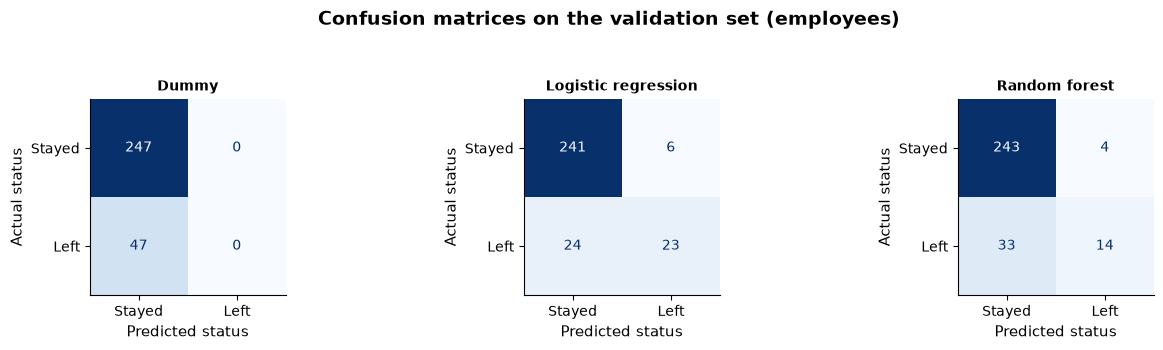

In [22]:
fig, axes = make_grid(len(MODELS), panel_height=3.8)
for ax, (name, pipeline) in zip(axes, MODELS.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_val,
        pipeline.predict(X_val),
        display_labels=["Stayed", "Left"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Predicted status")
    ax.set_ylabel("Actual status")
    ax.grid(False)
fig.suptitle(
    "Confusion matrices on the validation set (employees)",
    fontsize=14,
    fontweight="bold",
)
plt.show()

The dummy reaches 0.84 accuracy without finding a single leaver, so accuracy cannot guide us and we will rely on the PR-AUC, where the dummy sits at the 0.16 chance level.

The random forest memorizes the sub-train, with a PR-AUC of 1.00 against 0.55 on validation, while the logistic regression drops less, from 0.74 to 0.61.

On validation, the logistic regression finds 49% of the leavers and the forest only 30%, with a precision near 0.8 for both. The models are cautious and miss most leavers, which we will address with class weights and the decision threshold.

The validation set holds only 47 leavers, so one leaver moves the recall by about 2 points, and the gap between the two models is not conclusive yet.

We draw the precision-recall curves of the two models on both sets, with the business rule as a single point, to compare them across all thresholds.

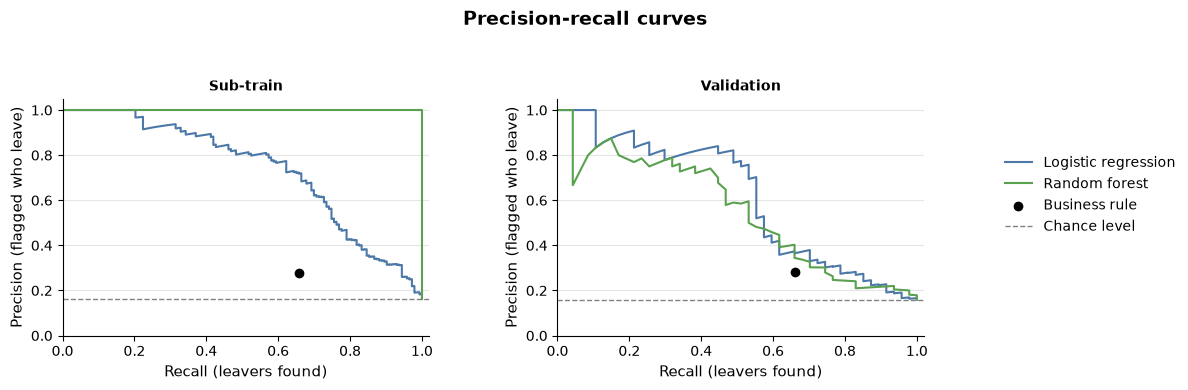

In [23]:
CURVE_COLORS = {"Logistic regression": RATE_BAR_COLOR, "Random forest": "#59a14f"}

fig, axes = make_grid(len(EVALUATION_SETS), panel_height=4.2, n_cols=2, width=12)
for ax, (set_name, (X_part, y_part)) in zip(axes, EVALUATION_SETS.items()):
    for name, color in CURVE_COLORS.items():
        precision, recall, _ = precision_recall_curve(
            y_part, probabilities[name, set_name]
        )
        ax.plot(recall, precision, color=color, label=name)
    rule_predicted = apply_business_rule(X_part)
    ax.scatter(
        recall_score(y_part, rule_predicted),
        precision_score(y_part, rule_predicted),
        color="black",
        zorder=3,
        label=RULE_NAME,
    )
    ax.axhline(
        y_part.mean(),
        color="gray",
        linestyle="--",
        linewidth=1,
        label="Chance level",
    )
    ax.set_title(set_name, fontsize=10)
    ax.set_xlabel("Recall (leavers found)")
    ax.set_ylabel("Precision (flagged who leave)")
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.05)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside right center")
fig.suptitle("Precision-recall curves", fontsize=14, fontweight="bold")
plt.show()

On validation, the business rule finds 66% of the leavers with a precision of 0.28, well above the chance level. At the same recall, both models reach about 0.4, so they already beat the rule.

The logistic regression is not clearly above the forest on validation, since the two curves stay close to each other. Past a recall of 0.8, both curves fall back toward the chance level, while the forest stays at 1.0 on the sub-train.

We plot the predicted probabilities by actual status, to see how well each model separates the leavers from the stayers around the default 0.5 threshold.

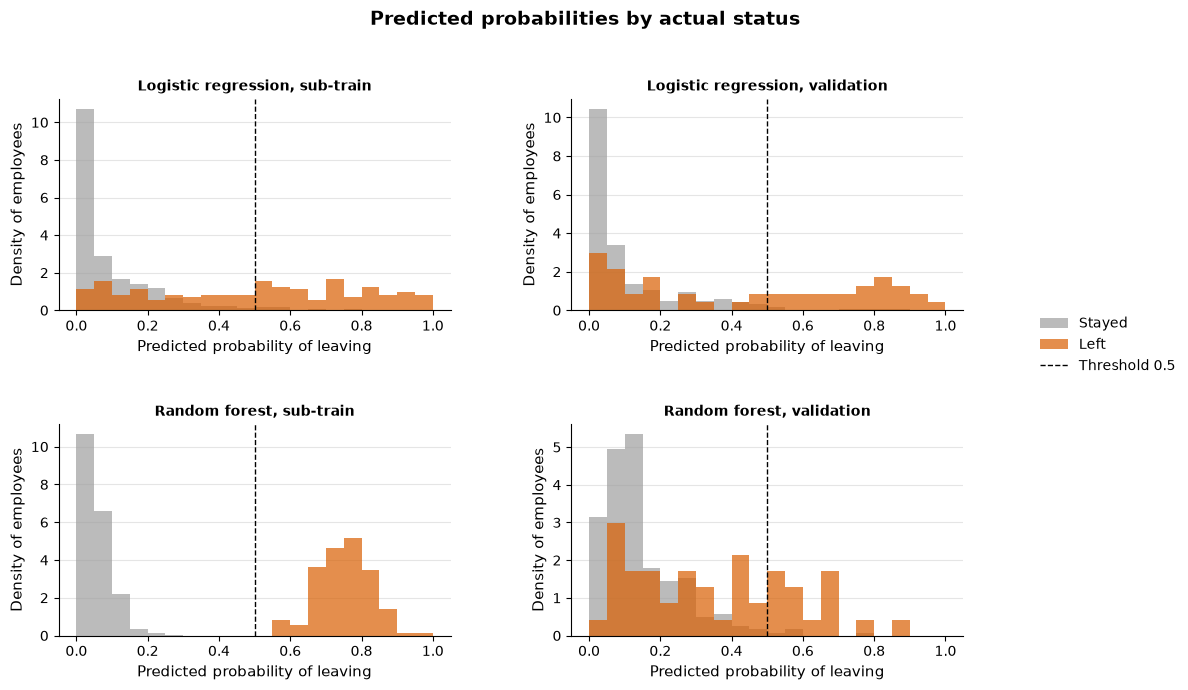

In [24]:
SCORED_MODELS = ["Logistic regression", "Random forest"]

fig, axes = make_grid(4, panel_height=3.6, n_cols=2, width=12)
panels = [(name, set_name) for name in SCORED_MODELS for set_name in EVALUATION_SETS]
bins = np.linspace(0, 1, 21)
for ax, (name, set_name) in zip(axes, panels):
    y_part = EVALUATION_SETS[set_name][1]
    scores = probabilities[name, set_name]
    for label, value in (("Stayed", 0), ("Left", 1)):
        ax.hist(
            scores[y_part.to_numpy() == value],
            bins=bins,
            density=True,
            alpha=0.7,
            color=TARGET_COLORS[label],
            label=label,
        )
    ax.axvline(0.5, color="black", linestyle="--", linewidth=1, label="Threshold 0.5")
    ax.set_title(f"{name}, {set_name.lower()}", fontsize=10)
    ax.set_xlabel("Predicted probability of leaving")
    ax.set_ylabel("Density of employees")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside right center")
fig.suptitle(
    "Predicted probabilities by actual status",
    fontsize=14,
    fontweight="bold",
)
plt.show()

The logistic regression pushes most stayers below 0.1 but spreads the leavers over the whole range, so many of them fall under the 0.5 threshold, which fits its recall of 0.49.

The random forest separates the two groups perfectly on the sub-train, with every leaver above 0.5. On validation, almost no leaver passes 0.7 and most sit below 0.5.

A lower threshold would find more leavers but also flag more stayers, because the two groups overlap between 0.1 and 0.4, especially with the forest.